# EDA: Predator Fish Invasion on a Riverine Food Web Data Set

### *John Tran — SEIS 631*

## Setup and loading

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("sia_dat.csv")
print(df.dtypes)

sample_id          str
site_number      int64
site_name          str
species            str
species_id         str
flathead           str
d_15N          float64
d_13C          float64
TN             float64
TC             float64
university         str
length_mm      float64
dtype: object


In [3]:
df.head()

,sample_id,site_number,site_name,species,species_id,flathead,d_15N,d_13C,TN,TC,university,length_mm
0,SIA1-001,1,Clemson Island,Algae,ALGE,Y,5.79,-21.20,1.05,9.50,PSU,NaN
1,SIA1-002,1,Clemson Island,Algae,ALGE,Y,6.19,-21.48,0.60,7.17,PSU,NaN
2,SIA1-003,1,Clemson Island,Algae,ALGE,Y,6.29,-20.68,0.71,8.00,PSU,NaN
3,SIA1-004,1,Clemson Island,Algae,ALGE,Y,6.28,-20.28,0.62,5.52,PSU,NaN
4,SIA1-005,1,Clemson Island,Algae,ALGE,Y,6.21,-18.52,1.34,11.57,PSU,NaN


In [4]:
# Inspecting sorted data by site and species
df.sort_values(["site_number", "species"], ascending=True).head(10)

,sample_id,site_number,site_name,species,species_id,flathead,d_15N,d_13C,TN,TC,university,length_mm
0,SIA1-001,1,Clemson Island,Algae,ALGE,Y,5.79,-21.20,1.05,9.50,PSU,NaN
1,SIA1-002,1,Clemson Island,Algae,ALGE,Y,6.19,-21.48,0.60,7.17,PSU,NaN
2,SIA1-003,1,Clemson Island,Algae,ALGE,Y,6.29,-20.68,0.71,8.00,PSU,NaN
3,SIA1-004,1,Clemson Island,Algae,ALGE,Y,6.28,-20.28,0.62,5.52,PSU,NaN
4,SIA1-005,1,Clemson Island,Algae,ALGE,Y,6.21,-18.52,1.34,11.57,PSU,NaN
5,SIA1-006,1,Clemson Island,Algae,ALGE,Y,6.07,-22.20,0.71,7.86,PSU,NaN
6,SIA1-007,1,Clemson Island,Algae,ALGE,Y,6.29,-22.18,0.69,8.40,PSU,NaN
183,SIF1-2-001,1,Clemson Island,Channel,CHCF,Y,12.37,-22.91,14.48,44.49,PSU,650.0
184,SIF1-2-002,1,Clemson Island,Channel,CHCF,Y,13.52,-22.61,14.11,44.07,PSU,695.0
185,SIF1-2-003,1,Clemson Island,Channel,CHCF,Y,12.98,-22.70,14.01,44.08,PSU,620.0


In [5]:
temp = df.copy()
# Summary stats for stable isotope ratios and body length
print("Summary Statistics:")
print(temp[['d_15N', 'd_13C', 'length_mm']].describe())

Summary Statistics:
            d_15N       d_13C    length_mm
count  585.000000  585.000000   451.000000
mean    11.313350  -23.573983   317.104213
std      2.597517    2.943347   305.414025
min      4.500000  -34.600000    10.500000
25%      9.700000  -25.300000    20.000000
50%     11.350000  -23.200000   257.000000
75%     13.300000  -21.900000   601.500000
max     16.600000  -13.900000  1119.000000


## 1. Provenance & Scope

- **Source & Collection:** The dataset (`sia_dat.csv`) originates from riverine food web studies investigating an invasive catfish population across various field sites (like Clemson Island and West Falls) and was compiled by academic researchers (PSU, MSU).
- **Dataset Purpose:** The dataset records continuous numerical metrics for stable isotope measurements (`d_13N`, `d_13C`, and organism length in millimeters) alongside categorical site flags `flathead` to evaluate distributional properties, summary statistics, and relationships.

## 2. Structure & quality

In [6]:
# Quality Check -- df.isna().sum()
df.isna().sum()

sample_id        0
site_number      0
site_name        0
species          0
species_id       0
flathead         0
d_15N            0
d_13C            0
TN               0
TC               0
university       0
length_mm      134
dtype: int64

##### Missing Values
By using `df.isna().sum()` I checked for missing values across columns.

Most columns like `site_name`, `species`, `d_15N`, and `d_13C` have 0 missing values, while `length_mm` has 134 missing values. This makes sense because plants like Algae and Eelgrass don't have body length measurements recorded. Length would only apply to fish and other animals.

In [7]:
# Quality Check -- duplicate checks
df.duplicated().sum()

np.int64(0)

In [8]:
# See duplicate rows if any
df[df.duplicated(keep=False)]

,sample_id,site_number,site_name,species,species_id,flathead,d_15N,d_13C,TN,TC,university,length_mm


##### Duplicate Checks
By using `df.duplicated().sum()`, I checked for identical rows across the dataset.
There are no unexpected duplicates in this dataset.

## 3. Distributions

I believe the key variables for our ecological analysis are **`d_15N`** (trophic position proxy), **`d_13C`** (carbon source baseline), and **`length_mm`** (organism body size).

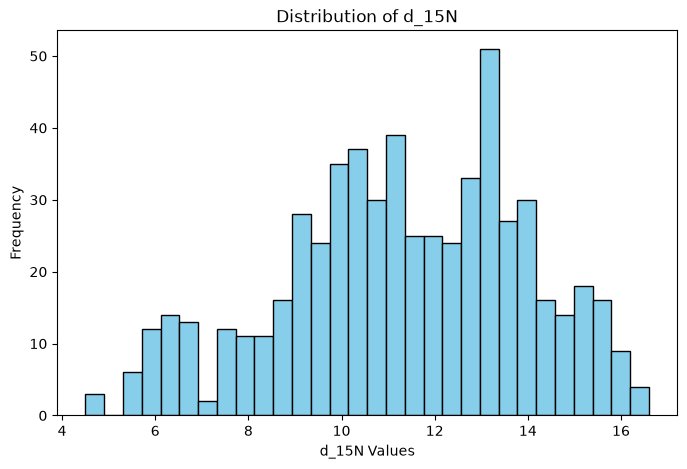

--- d_15N Summary Statistics ---
count    585.000000
mean      11.313350
std        2.597517
min        4.500000
25%        9.700000
50%       11.350000
75%       13.300000
max       16.600000
Name: d_15N, dtype: float64
Median: 11.35
Variance: 6.7470962896616316


In [9]:
# Distribution and summary statistics for d_15N
plt.figure(figsize=(8, 5))
plt.hist(df["d_15N"], bins=30, edgecolor="black", color="skyblue")
plt.title("Distribution of d_15N")
plt.xlabel("d_15N Values")
plt.ylabel("Frequency")
plt.show()

print("--- d_15N Summary Statistics ---")
print(df["d_15N"].describe())
print("Median:", df["d_15N"].median())
print("Variance:", df["d_15N"].var())

### d_15N
The histogram for `d_15N` shows a median value of 11.35, a mean of 11.31, a standard deviation of 2.51, and a variance of 6.75. The values range from a minimum baseline of 4.50 up to a maximum of 16.60. The frequency distribution displays a relatively balanced spread across the riverine food web samples.

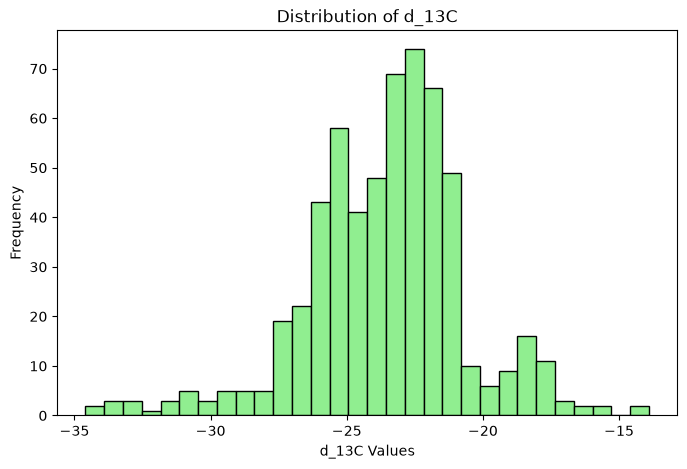

--- d_13C Summary Statistics ---
count    585.000000
mean     -23.573983
std        2.943347
min      -34.600000
25%      -25.300000
50%      -23.200000
75%      -21.900000
max      -13.900000
Name: d_13C, dtype: float64
Median: -23.2
Variance: 8.663292157241541


In [10]:
# Distribution and summary statistics for d_13C
plt.figure(figsize=(8, 5))
plt.hist(df["d_13C"], bins=30, edgecolor="black", color="lightgreen")
plt.title("Distribution of d_13C")
plt.xlabel("d_13C Values")
plt.ylabel("Frequency")
plt.show()

print("--- d_13C Summary Statistics ---")
print(df["d_13C"].describe())
print("Median:", df["d_13C"].median())
print("Variance:", df["d_13C"].var())

### d_13C
The distribution of `d_13C` values centers around a median of -23.20, a mean of -23.57, a standard deviation of 2.94, and a variance of 8.66. The measurements span from -34.60 to -13.90 across all recorded samples.

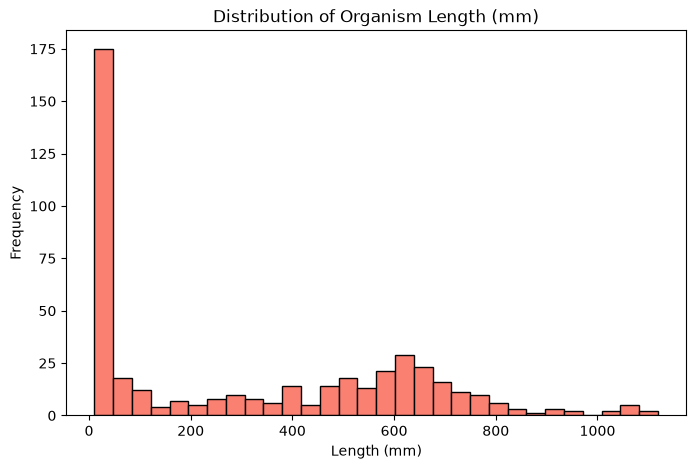

--- length_mm Summary Statistics ---
count     451.000000
mean      317.104213
std       305.414025
min        10.500000
25%        20.000000
50%       257.000000
75%       601.500000
max      1119.000000
Name: length_mm, dtype: float64
Median: 257.0
Variance: 93277.72689332347


In [11]:
# Drop missing values for length_mm before analyzing distribution
valid_lengths = df["length_mm"].dropna()

plt.figure(figsize=(8, 5))
plt.hist(valid_lengths, bins=30, edgecolor="black", color="salmon")
plt.title("Distribution of Organism Length (mm)")
plt.xlabel("Length (mm)")
plt.ylabel("Frequency")
plt.show()

print("--- length_mm Summary Statistics ---")
print(valid_lengths.describe())
print("Median:", valid_lengths.median())
print("Variance:", valid_lengths.var())

### length_mm
After filtering out missing values, n = 451. The graph has a heavy right skew. There is a lot of small organisms at the lower end (minimum of 10.5 mm, first quartile at 20.0 mm which is useful for mean when graph has a skew ), resulting in a median length of 257.0 mm that is lower than the mean of 317.10 mm. The long right tail stretches to a maximum of 1119.0 mm. This most likely represents larger aquatic animals.

In [12]:
# Check species group counts
print(df.groupby("species")[["d_15N", "d_13C", "length_mm"]].mean())

                d_15N      d_13C   length_mm
species                                     
Algae        7.722135 -25.577079         NaN
Channel     13.083451 -23.921416  576.433628
Crayfish    10.104783 -23.862899   29.125000
Eelgrass     7.895000 -22.910000         NaN
Flathead    15.037975 -23.391772  724.797468
Prey        11.409516 -24.080484  105.166667
Smallmouth  13.190889 -23.478889  293.400000
Snail       10.263889 -21.380278   10.500000


### Species Trophic Summary
Grouping by species reveals clear trophic stratification, with primary producers at the lowest `d_15N` levels and Flathead Catfish at the highest.

## 4. Relationships

I believe two important relationships could be:
1. Carbon (`d_13C`) vs. nitrogen (`d_15N`) isotopes grouped by species.
2. Nitrogen isotope values (`d_15N`) across our categorical site invasion flag (`flathead`).

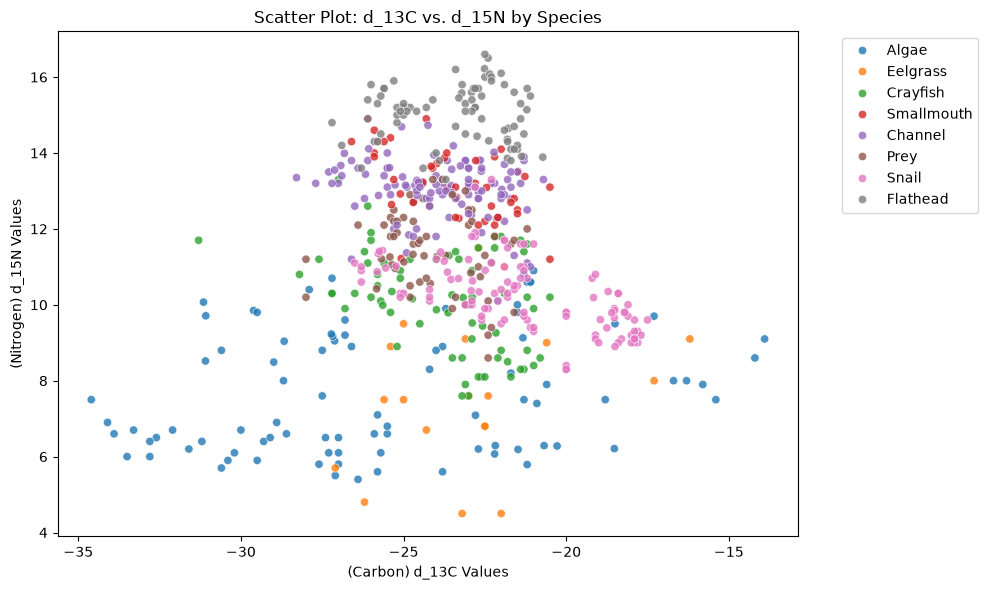

C:\Users\inotp\AppData\Local\Temp\ipykernel_11068\1475704845.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


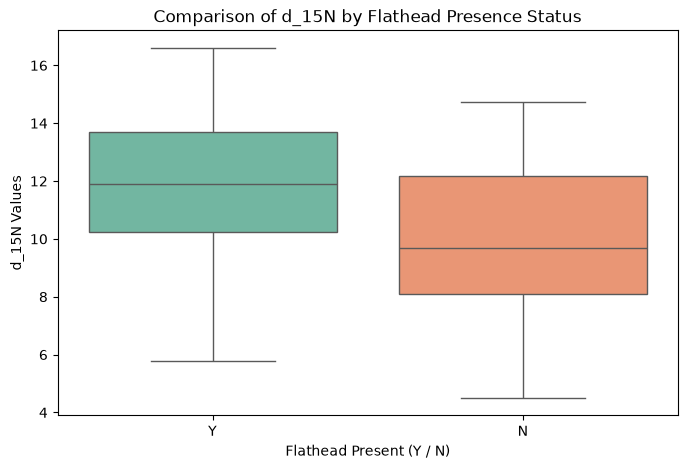

--- d_15N Summary Statistics by Flathead Status ---
          count       mean       std   min    25%   50%     75%    max
flathead                                                              
N         170.0   9.774059  2.507099  4.50   8.10   9.7  12.175  14.73
Y         415.0  11.943904  2.362265  5.79  10.23  11.9  13.710  16.60


In [13]:
# Scatter plot of d_13C vs d_15N, colored by species
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df, 
    x="d_13C", 
    y="d_15N", 
    hue="species", 
    palette="tab10", 
    alpha=0.8
)
plt.title("Scatter Plot: d_13C vs. d_15N by Species")
plt.xlabel("(Carbon) d_13C Values")
plt.ylabel("(Nitrogen) d_15N Values")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

# Grouped box plot comparing d_15N across the flathead presence flag (Y/N)
plt.figure(figsize=(8, 5))
sns.boxplot(
    data=df, 
    x="flathead", 
    y="d_15N", 
    palette="Set2"
)
plt.title("Comparison of d_15N by Flathead Presence Status")
plt.xlabel("Flathead Present (Y / N)")
plt.ylabel("d_15N Values")
plt.show()

# Print grouped summary statistics
print("--- d_15N Summary Statistics by Flathead Status ---")
print(df.groupby("flathead")["d_15N"].describe())

### `d_13C` vs. `d_15N`
The scatter plot displays the distribution of `d_13C` and `d_15N` colored by species. In the plot, the species are layered on top of eachother: primary producers like Algae and Eelgrass cluster at the bottom with lower `d_15N` values ($\approx$ 4-8), while consumers and apex predators like Flathead Catfish are in the upper tier (`d_15N` $\approx$ 14–17).

### `flathead` vs. `d_15N`
Comparing `d_15N` values grouped by the `flathead` presence flag (`Y` vs. `N`) shows a clear difference in distributions between subsets. Observations where `flathead = Y` have a higher average nitrogen isotope value (mean = 11.94, median = 11.90) compared to records where `flathead = N` (n = 170, mean = 9.77, median = 9.70).

## 5. Readiness

The dataset is cleaned, structured, and verified for exploratory data analysis. The processed continuous variables (`d_15N`, `d_13C`, and `length_mm`) and categorical flags (`flathead`) are fully prepared to support further statistical analysis, hypothesis testing, and modeling.

## 6. Your Questions

1. Do samples associated with Flathead Catfish exhibit significantly higher nitrogen isotope values (`d_15N`) compared to other riverine groups?
    - **Answer:** Yes, group summaries and data distributions confirm that records with `flathead = Y` have substantially higher mean `d_15N` values than uninvaded subsets.

2. Do distinct species groups exhibit clustering along the carbon (`d_13C`) and nitrogen (`d_15N`) axes a certain way?
    - **Answer:** Yes, the scatter plot colored by species shows clear separation of each species by layer, indicating that different groups use different parts of the carbon pools and occupy separate tiers within the sampled ecosystem.

## Reflection

Adapting this EDA from a video game dataset (`steam.csv`) to an ecological isotope dataset (`sia_dat.csv`) required replacing pricing, release years, and user reviews with nitrogen/carbon stable isotopes and organism length measurements. I was mostly confused about how to create the plot for the layered tiers of species, so AI helped for graphs like that. AI also helped me reword my analysis of each graph. I can explain how to read this type of scatter plot graph no without AI when before I couldn't. This one took a while because of switching datasets and having loads of work from other classes. I am just glad to have gotten this done.